# 04. Normal yield (trend) and dryness colour options

Two Layer 2 decisions, see `specs/tasks-layer2.md` and `specs/layer2-impact.md`. Both are now decided (section 7):

1. **Normal yield.** Explored here first as a straight line fitted on 1987 to 2008 only (sections 3 to 5). That line drifts, so section 6 compares it with two other fits. Decided: a straight line through the 10 years before each year.
2. **Colour thresholds.** Section 5 shows the options. Decided: PAGASA rainfall bands.

Split (same as Layer 1): train 1987 to 2008, validate 2009 to 2016, test 2017 to 2026.

This notebook builds no model and changes no files.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../backend").resolve()))  # so `app` can be imported

from app.data.load_crops import load_crops
from app.data.load_rainfall import load_rainfall
from app.layer1_forecast.labels import find_events

TRAIN_END, VALID_END = 2008, 2016
MIN_YEARS = 10  # decided: at least 10 years of yield per province, crop and quarter

crops = load_crops()
rain = load_rainfall()
lookup = pd.read_csv("../backend/app/data/province_lookup.csv", dtype=str)
print(f"crops {crops.shape}, rainfall {rain.shape}, lookup {lookup.shape}")

crops (76800, 7), rainfall (14823, 8), lookup (88, 5)


## 1. Join crops to rainfall

Crops use the province name, rainfall uses the PCODE. The lookup has one row per map shape, so merged provinces (Davao del Sur, Maguindanao) appear twice and NCR, Isabela City and the Special Geographic Area have no crop name. We keep one row per crop name first. Without this, those provinces would get double rows.

In [2]:
province_to_pcode = lookup[["crop_name", "rain_pcode"]].dropna().drop_duplicates()

data = crops.merge(province_to_pcode, left_on="province", right_on="crop_name",
                   how="left", validate="many_to_one").drop(columns="crop_name")
data = data.merge(rain[["pcode", "year", "quarter", "rain_pct_of_normal"]],
                  left_on=["rain_pcode", "year", "quarter"], right_on=["pcode", "year", "quarter"],
                  how="left", validate="many_to_one").drop(columns="pcode")

assert len(data) == len(crops), "the join duplicated rows"
assert data["rain_pcode"].notna().all(), "a crop province has no rainfall code"
print(f"{len(data)} rows, same as crops. Rows with no rainfall value: {data['rain_pct_of_normal'].isna().sum()}")

76800 rows, same as crops. Rows with no rainfall value: 480


## 2. El Nino, La Nina and neutral quarters

Rule (decided, accepted by the user):

- Events come from `find_events` (Layer 1 rule: at least 5 months in a row with ONI >= +0.5). The ongoing event ends at the last ONI month.
- La Nina events use the same rule on -ONI (at least 5 months in a row with ONI <= -0.5).
- A quarter is **El Nino** when at least 2 of its 3 months are inside an El Nino event, and **La Nina** the same way.
- A quarter is **Neutral** only when none of its months touch any event. Quarters that touch an event with only 1 month are "Mixed" and left out of comparisons.
- Single warm months that never become an event do not count.

In [3]:
enso = pd.read_csv("../data/processed/enso_monthly.csv", parse_dates=["date"])[["date", "oni"]].dropna()
last_month = enso["date"].max()


def months_by_event(events):
    """Map each month inside an event to the event's start month."""
    out = {}
    for e in events.itertuples():
        end = e.end_month if pd.notna(e.end_month) else last_month  # ongoing event
        for month in pd.date_range(e.start_month, end, freq="MS"):
            out[month] = e.start_month
    return out


el_nino_events = find_events(enso)
el_nino_month = months_by_event(el_nino_events)
la_nina_month = months_by_event(find_events(enso.assign(oni=-enso["oni"])))  # mirrored rule

months = pd.DataFrame({"date": pd.date_range("1987-01-01", "2026-12-01", freq="MS")})
months["year"], months["quarter"] = months["date"].dt.year, months["date"].dt.quarter
months["el_nino"] = months["date"].isin(el_nino_month.keys())
months["la_nina"] = months["date"].isin(la_nina_month.keys())
months["event_start"] = months["date"].map(el_nino_month)

phase = months.groupby(["year", "quarter"]).agg(
    el_nino_months=("el_nino", "sum"), la_nina_months=("la_nina", "sum"),
    event_start=("event_start", "min"))
phase["phase"] = np.select(
    [phase["el_nino_months"] >= 2, phase["la_nina_months"] >= 2,
     (phase["el_nino_months"] == 0) & (phase["la_nina_months"] == 0)],
    ["El Nino", "La Nina", "Neutral"], default="Mixed")
phase = phase.reset_index()
phase["period"] = np.select([phase["year"] <= TRAIN_END, phase["year"] <= VALID_END],
                            ["train", "validate"], default="test")
print(phase["phase"].value_counts().to_string())
print()
print("El Nino events since 1987:")
print(el_nino_events[el_nino_events["start_month"] >= "1986-01-01"][
    ["start_month", "end_month", "duration_months", "peak_oni", "strength"]].to_string(index=False))

phase
Neutral    64
La Nina    42
El Nino    41
Mixed      13

El Nino events since 1987:
start_month  end_month  duration_months  peak_oni strength
 1986-09-01 1988-01-01               17      1.49 moderate
 1991-06-01 1992-06-01               13      1.54   strong
 1994-10-01 1995-02-01                5      0.97     weak
 1997-05-01 1998-04-01               12      2.37   strong
 2002-07-01 2003-02-01                8      1.19 moderate
 2004-08-01 2005-02-01                7      0.71     weak
 2006-09-01 2007-01-01                5      0.88     weak
 2009-07-01 2010-03-01                9      1.50   strong
 2014-10-01 2016-05-01               20      2.59   strong
 2018-09-01 2019-06-01               10      1.05 moderate
 2019-10-01 2020-03-01                6      0.75     weak
 2023-06-01 2024-04-01               11      1.99   strong
 2026-05-01        NaT                5      2.46   strong


## 3. Fit the trend line (training years only)

For each province, crop and quarter (a "cell") with at least 10 years of yield in total, fit a straight line on 1987 to 2008 only. Three groups:

- **cannot fit:** under 2 training years (no line possible)
- **under 10 training years:** a line exists but rests on few points
- **10 or more training years:** the reliable group

The median training area shows quarters where the crop is barely planted (a yield on a few hectares is mostly noise).

In [4]:
CELL = ["crop_type", "province", "quarter"]
with_yield = data[data["yield_t_per_ha"].notna()]
total_years = with_yield.groupby(CELL).size().rename("total_years")


def fit_line(group):
    if len(group) < 2:
        return pd.Series({"slope": np.nan, "intercept": np.nan})
    slope, intercept = np.polyfit(group["year"], group["yield_t_per_ha"], 1)
    return pd.Series({"slope": slope, "intercept": intercept})


train_rows = with_yield[with_yield["year"] <= TRAIN_END]
fits = train_rows.groupby(CELL)[["year", "yield_t_per_ha"]].apply(fit_line)
fits["train_years"] = train_rows.groupby(CELL).size()
fits["median_train_area_ha"] = train_rows.groupby(CELL)["area_ha"].median()

cell_table = total_years[total_years >= MIN_YEARS].to_frame().join(fits, how="left")
cell_table["train_years"] = cell_table["train_years"].fillna(0).astype(int)
cell_table["group"] = np.select(
    [cell_table["train_years"] < 2, cell_table["train_years"] < 10],
    ["cannot fit (<2 training years)", "under 10 training years"], default="10+ training years")
print(f"Cells passing the 10-year rule: {len(cell_table)}")
print(cell_table["group"].value_counts().to_string())

Cells passing the 10-year rule: 1839
group
10+ training years                1661
under 10 training years            126
cannot fit (<2 training years)      52


In [5]:
print("Median training area (ha) of the reliable cells:")
reliable = cell_table[cell_table["group"] == "10+ training years"]
print(reliable["median_train_area_ha"].describe().round(1).to_string())
for floor in [10, 50, 100, 500]:
    print(f"  reliable cells with median training area under {floor} ha: "
          f"{(reliable['median_train_area_ha'] < floor).sum()}")
print()
print("Cells that cannot be fitted or have under 10 training years:")
print(cell_table[cell_table["group"] != "10+ training years"]
      .sort_values(["group", "train_years"])[["total_years", "train_years", "group"]].to_string())

Median training area (ha) of the reliable cells:
count      1661.0
mean       7580.4
std       13304.5
min           1.0
25%         430.0
50%        2575.5
75%        9101.0
max      160804.0
  reliable cells with median training area under 10 ha: 15
  reliable cells with median training area under 50 ha: 93
  reliable cells with median training area under 100 ha: 171
  reliable cells with median training area under 500 ha: 440

Cells that cannot be fitted or have under 10 training years:
                                             total_years  train_years                           group
crop_type       province            quarter                                                          
Corn            Batanes             1                 14            0  cannot fit (<2 training years)
                                    2                 15            0  cannot fit (<2 training years)
                                    3                 15            0  cannot fit (<2 training ye

## 4. Yield change against the trend

Yield change % is only computed where the trend is above 0 in that year (a falling line can cross zero when extended, and the percent would blow up). From here on, the analysis uses the **reliable cells only** (10 or more training years), so short lines do not distort the numbers.

In [6]:
d = data.merge(cell_table[cell_table["group"] == "10+ training years"]
               [["slope", "intercept"]].reset_index(), on=CELL, how="inner")
d["trend"] = d["intercept"] + d["slope"] * d["year"]
d["yield_change_pct"] = ((d["yield_t_per_ha"] - d["trend"]) / d["trend"] * 100).where(d["trend"] > 0)
d = d.merge(phase[["year", "quarter", "phase", "period", "event_start"]],
            on=["year", "quarter"], how="left", validate="many_to_one")

has_yield = d["yield_t_per_ha"].notna()
not_positive = has_yield & (d["trend"] <= 0)
print(f"Cell-years with a yield: {has_yield.sum()}")
print(f"Cell-years where the trend is 0 or below (no percent): {not_positive.sum()}")
print(d[not_positive].groupby("crop_type").size().to_string())

Cell-years with a yield: 62880
Cell-years where the trend is 0 or below (no percent): 73
crop_type
Corn             29
Rainfed Palay     8
White Corn       14
Yellow Corn      22


### Drift check

If the extended line still fits, the **median** yield change in neutral quarters should stay near 0 in validation and test years. The median is used because one odd cell can swing a mean.

      median  size
year              
2006     4.8   388
2007     5.3   385
2008     4.5   431
2009     5.9   387
2012     0.6  1222
2013     1.0  1634
2014     0.8  1225
2016    -1.3   833
2017    -1.9  1227
2018    -1.5   386
2019    -3.2   422
2020    -5.3   388
2024    -9.7   830
2025    -9.4  1617
2026   -11.1   410

period
test       -6.1
train      -0.5
validate    1.1


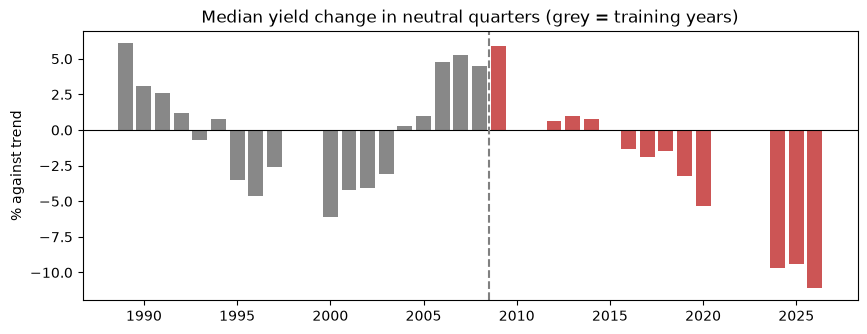

In [7]:
neutral = d[(d["phase"] == "Neutral") & d["yield_change_pct"].notna()]
drift = neutral.groupby("year")["yield_change_pct"].agg(["median", "size"]).round(1)
print(drift[drift.index > TRAIN_END - 3].to_string())
print()
print(neutral.groupby("period")["yield_change_pct"].median().round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(drift.index, drift["median"], color=["#888" if y <= TRAIN_END else "#c55" for y in drift.index])
ax.axhline(0, color="black", lw=0.8)
ax.axvline(TRAIN_END + 0.5, ls="--", color="gray")
ax.set_title("Median yield change in neutral quarters (grey = training years)")
ax.set_ylabel("% against trend")
plt.show()

### Two examples

Actual yield and the trend line (fitted on the grey part only) for the quarter with the largest training area.

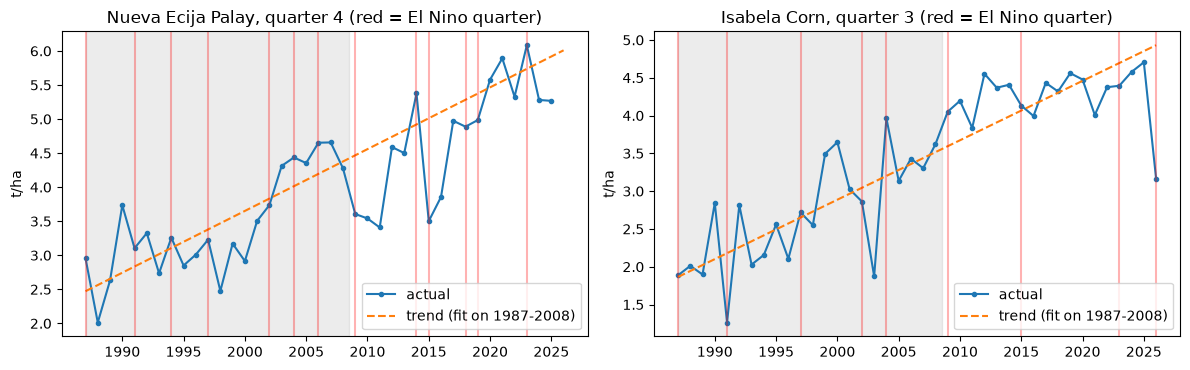

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (crop, province) in zip(axes, [("Palay", "Nueva Ecija"), ("Corn", "Isabela")]):
    rows = d[(d["crop_type"] == crop) & (d["province"] == province)]
    biggest_quarter = rows[rows["year"] <= TRAIN_END].groupby("quarter")["area_ha"].median().idxmax()
    rows = rows[rows["quarter"] == biggest_quarter].sort_values("year")
    ax.plot(rows["year"], rows["yield_t_per_ha"], "o-", ms=3, label="actual")
    ax.plot(rows["year"], rows["trend"], "--", label="trend (fit on 1987-2008)")
    ax.axvspan(1987, TRAIN_END + 0.5, color="gray", alpha=0.15)
    for _, r in rows[rows["phase"] == "El Nino"].iterrows():
        ax.axvline(r["year"], color="red", alpha=0.3)
    ax.set_title(f"{province} {crop}, quarter {biggest_quarter} (red = El Nino quarter)")
    ax.set_ylabel("t/ha")
    ax.legend()
plt.tight_layout()
plt.show()

### El Nino against neutral quarters

A first sign of whether there is anything to predict. This is not a model.

In [9]:
compare = d[d["phase"].isin(["El Nino", "Neutral"]) & d["yield_change_pct"].notna()]
by_period = compare.pivot_table(index="period", columns="phase", values="yield_change_pct",
                                aggfunc="median").round(1)
by_period["difference"] = by_period["El Nino"] - by_period["Neutral"]
print("Median yield change %, all reliable cells:")
print(by_period.loc[["train", "validate", "test"]].to_string())
print()
by_crop = compare.pivot_table(index="crop_type", columns="phase", values="yield_change_pct",
                              aggfunc="median").round(1)
by_crop["difference"] = by_crop["El Nino"] - by_crop["Neutral"]
print("By crop type, all years:")
print(by_crop.to_string())

Median yield change %, all reliable cells:
phase     El Nino  Neutral  difference
period                                
train        -1.2     -0.5        -0.7
validate     -1.7      1.1        -2.8
test         -7.8     -6.1        -1.7

By crop type, all years:
phase            El Nino  Neutral  difference
crop_type                                    
Corn                -0.9     -0.1        -0.8
Irrigated Palay     -2.8     -1.3        -1.5
Palay               -2.6     -1.2        -1.4
Rainfed Palay       -2.5     -0.8        -1.7
White Corn          -0.1      1.1        -1.2
Yellow Corn         -3.9     -2.3        -1.6


## 5. Colour threshold options (decided: option R, PAGASA rainfall bands)

### Distributions, El Nino against neutral quarters

Rainfall % of normal is per rainfall area and quarter (not repeated per crop).

Rainfall % of normal:
          count   mean   std   min   10%   25%   50%    75%    max
phase                                                             
El Nino  3321.0   72.5  25.2  13.9  40.5  55.4  72.0   88.2  238.3
Neutral  5103.0  100.5  29.3  27.7  63.6  82.0  98.7  118.1  252.5

Yield change %:
           count  mean     std   min   10%   25%  50%   75%       max
phase                                                                
El Nino  16221.0  12.2   684.5 -89.4 -30.2 -15.9 -2.3  11.1   74621.9
Neutral  24683.0  22.3  2871.0 -89.5 -26.3 -12.9 -0.9  11.1  450843.6


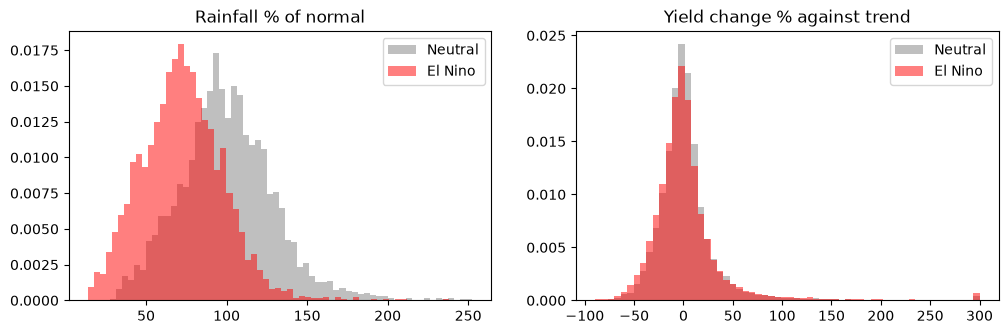

In [10]:
rain_phase = rain.merge(phase, on=["year", "quarter"], how="inner")
rain_phase = rain_phase[rain_phase["year"] >= 1987]
print("Rainfall % of normal:")
print(rain_phase[rain_phase["phase"].isin(["El Nino", "Neutral"])]
      .groupby("phase")["rain_pct_of_normal"].describe(percentiles=[.1, .25, .5, .75]).round(1).to_string())
print()
print("Yield change %:")
print(compare.groupby("phase")["yield_change_pct"].describe(percentiles=[.1, .25, .5, .75]).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (frame, column, title) in zip(axes, [
        (rain_phase, "rain_pct_of_normal", "Rainfall % of normal"),
        (compare, "yield_change_pct", "Yield change % against trend")]):
    for name, colour in [("Neutral", "gray"), ("El Nino", "red")]:
        values = frame.loc[frame["phase"] == name, column].clip(-100, 300)
        ax.hist(values, bins=60, density=True, alpha=0.5, color=colour, label=name)
    ax.set_title(title)
    ax.legend()
plt.show()

### The two El Nino events used to judge

- **2015-16** (validation years): used to judge the options.
- **2023-24** (test years): shown for information only, not used to choose.

Event quarters are the El Nino quarters (2 or more months inside the event) of the event that covers June 2015 and June 2023.

In [11]:
def event_containing(month):
    start = el_nino_month[pd.Timestamp(month)]
    return phase[(phase["event_start"] == start) & (phase["phase"] == "El Nino")][["year", "quarter"]]


judge_events = {"2015-16 (validate)": event_containing("2015-06-01"),
                "2023-24 (test, info only)": event_containing("2023-06-01")}
for name, quarters in judge_events.items():
    print(name, [f"{y} Q{q}" for y, q in quarters.itertuples(index=False)])

2015-16 (validate) ['2014 Q4', '2015 Q1', '2015 Q2', '2015 Q3', '2015 Q4', '2016 Q1', '2016 Q2']
2023-24 (test, info only) ['2023 Q3', '2023 Q4', '2024 Q1']


### Option R: PAGASA rainfall categories

PAGASA's categories (source: PAGASA Dry Spell/Drought Assessment, 31 Dec 2023): 40% or less of normal = way below normal, 41 to 80% = below normal, 81 to 120% = near normal, above 120% = above normal.

For a three-colour dryness map: **red** 40% or less, **yellow** 41 to 80%, **green** above 80%. Near normal and above normal are both green, because neither is dry.

Counts are province-quarters (81 rainfall areas x the event quarters).

In [12]:
def colour_counts(values, red_max, yellow_max):
    colour = np.select([values <= red_max, values <= yellow_max], ["red", "yellow"], default="green")
    colour = pd.Series(colour, index=values.index).where(values.notna())
    return colour.value_counts().reindex(["green", "yellow", "red"], fill_value=0)


rows = []
for name, quarters in judge_events.items():
    event_rain = rain.merge(quarters, on=["year", "quarter"])["rain_pct_of_normal"]
    counts = colour_counts(event_rain, 40, 80)
    rows.append({"event": name, **counts.to_dict(), "total": counts.sum()})
print("Option R (PAGASA): red <= 40%, yellow 41-80%, green > 80%")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Per quarter, 2015-16:")
event_rain = rain.merge(judge_events["2015-16 (validate)"], on=["year", "quarter"])
print(event_rain.groupby(["year", "quarter"])["rain_pct_of_normal"]
      .apply(lambda v: colour_counts(v, 40, 80)).unstack().to_string())

Option R (PAGASA): red <= 40%, yellow 41-80%, green > 80%
                    event  green  yellow  red  total
       2015-16 (validate)    206     308   53    567
2023-24 (test, info only)    135     100    8    243

Per quarter, 2015-16:
              green  yellow  red
year quarter                    
2014 4           59      16    6
2015 1           16      58    7
     2           11      70    0
     3           37      44    0
     4           30      51    0
2016 1            6      35   40
     2           47      34    0


### Options Y: yield change cutoffs from our own data

Cutoffs are percentiles of yield change in the **training years only** (1987 to 2008), all reliable cells together. Red at or below the low percentile, yellow up to the high percentile, green above.

Counts are province-quarters for the two totals, Palay and Corn, in the event quarters. A province is counted once per quarter per crop.

In [13]:
train_change = d.loc[(d["period"] == "train"), "yield_change_pct"].dropna()
options = {"Y1: 10th / 25th percentile": (10, 25), "Y2: 20th / 40th percentile": (20, 40)}

print("Training percentiles per crop type (for information; the options use all crops together):")
print(d[d["period"] == "train"].groupby("crop_type")["yield_change_pct"]
      .quantile([.1, .2, .25, .4]).unstack().round(1).to_string())
print()

rows = []
for option, (low, high) in options.items():
    red_max, yellow_max = np.percentile(train_change, [low, high])
    for name, quarters in judge_events.items():
        for crop in ["Palay", "Corn"]:
            event_rows = d[d["crop_type"] == crop].merge(quarters, on=["year", "quarter"])
            counts = colour_counts(event_rows["yield_change_pct"], red_max, yellow_max)
            rows.append({"option": option, "cutoffs %": f"red <= {red_max:.1f}, yellow <= {yellow_max:.1f}",
                         "event": name, "crop": crop, **counts.to_dict(), "total": counts.sum()})
print(pd.DataFrame(rows).to_string(index=False))

Training percentiles per crop type (for information; the options use all crops together):
                 0.10  0.20  0.25  0.40
crop_type                              
Corn            -30.1 -19.6 -15.4  -6.4
Irrigated Palay -15.3  -9.0  -6.9  -2.4
Palay           -15.9  -9.5  -7.4  -2.5
Rainfed Palay   -22.5 -13.9 -10.8  -3.5
White Corn      -28.5 -18.1 -14.5  -5.8
Yellow Corn     -34.4 -21.3 -16.4  -5.5

                    option                     cutoffs %                     event  crop  green  yellow  red  total
Y1: 10th / 25th percentile red <= -23.9, yellow <= -10.7        2015-16 (validate) Palay    354     125   43    522
Y1: 10th / 25th percentile red <= -23.9, yellow <= -10.7        2015-16 (validate)  Corn    335      88   75    498
Y1: 10th / 25th percentile red <= -23.9, yellow <= -10.7 2023-24 (test, info only) Palay    100      66   58    224
Y1: 10th / 25th percentile red <= -23.9, yellow <= -10.7 2023-24 (test, info only)  Corn    141      23   54    218
Y2: 20th 

For reference: by construction, across all training quarters the percentile rule gives 10% red and 15% yellow for Y1, and 20% red and 20% yellow for Y2. An option is useful when the El Nino event shows clearly more red and yellow than that.

## 6. Comparing normal-yield fits

Section 4 showed that a line fitted once on 1987 to 2008 drifts: later years look worse than normal even without El Nino. Here three ways to build the normal are compared on the same data.

For each cell (province, crop, quarter) and each year Y:

- **(a) 1987-2008 line:** one straight line fitted on the training years (at least 2 yields), then extended to Y.
- **(b) all past years:** a straight line through every year before Y that has a yield. Needs at least 10 such years; gaps are allowed.
- **(c) last 10 years (decided):** a straight line through Y-10 to Y-1. All 10 years must have a yield.

Yield change % = (actual - normal) / normal x 100, only where the normal is above 0, for all three.

**Fair comparison:** all three are scored only on cell-years where every method gives a normal above 0. Because (c) needs 10 earlier years and the data starts in 1987, scoring starts in 1997, so "train" here means 1997 to 2008. Fit (a) is measured on the same years it was fitted on there (in-sample), so its train row looks better than it really is.

In [14]:
METHODS = ["a: 1987-2008 line", "b: all past years", "c: last 10 years"]


def changes_for_cell(group):
    """Yield change % under the three normals, for every year where (c) is defined."""
    yields = group.set_index("year")["yield_t_per_ha"]  # only years with a yield
    train = yields[yields.index <= TRAIN_END]
    fixed_line = np.polyfit(train.index, train.values, 1) if len(train) >= 2 else None
    rows = []
    for year, actual in yields.items():
        last10 = yields[(yields.index >= year - 10) & (yields.index < year)]
        if len(last10) < 10:  # (c) needs all 10 previous years
            continue
        past = yields[yields.index < year]  # at least 10 years, since last10 is inside it
        normals = [
            np.polyval(fixed_line, year) if fixed_line is not None else np.nan,
            np.polyval(np.polyfit(past.index, past.values, 1), year),
            np.polyval(np.polyfit(last10.index, last10.values, 1), year),
        ]
        rows.append({"year": year, **{m: (actual - n) / n * 100 if n > 0 else np.nan
                                      for m, n in zip(METHODS, normals)}})
    return pd.DataFrame(rows, columns=["year", *METHODS])


cmp = (with_yield.groupby(CELL)[["year", "yield_t_per_ha"]].apply(changes_for_cell)
       .reset_index(level=-1, drop=True).reset_index())
cmp[METHODS] = cmp[METHODS].astype(float)  # empty cells make the columns object type
cmp = cmp.merge(phase[["year", "quarter", "phase", "period"]], on=["year", "quarter"], how="left")
scored = cmp.dropna(subset=METHODS)  # same cell-years for all three methods
print(f"cell-years where (c) is defined: {len(cmp)}; scored by all three: {len(scored)}")
print(f"scored years: {scored['year'].min()} to {scored['year'].max()}")

cell-years where (c) is defined: 45364; scored by all three: 45099
scored years: 1997 to 2026


### Median yield change in neutral quarters, and the spread

If a normal fits, the median in neutral quarters should stay near 0 in every period. The spread is the interquartile range (75th minus 25th percentile): smaller means less noise.

In [15]:
neutral_cmp = scored[scored["phase"] == "Neutral"]
periods = ["train", "validate", "test"]
by_period = neutral_cmp.groupby("period")[METHODS]
medians = by_period.median().reindex(periods).T
spread = (by_period.quantile(0.75) - by_period.quantile(0.25)).reindex(periods).T
table = pd.concat({"median %": medians, "spread (IQR)": spread}, axis=1).round(1)
table.columns = [f"{kind}, {p}" for kind, p in table.columns]
print("train = 1997-2008, validate = 2009-2016, test = 2017-2026 (neutral quarters only)")
print(table.to_string())
print()
print("cell-years per period:", neutral_cmp["period"].value_counts().reindex(periods).to_dict())

train = 1997-2008, validate = 2009-2016, test = 2017-2026 (neutral quarters only)
                   median %, train  median %, validate  median %, test  spread (IQR), train  spread (IQR), validate  spread (IQR), test
a: 1987-2008 line             -0.9                 0.8            -6.9                 15.4                    27.1                35.9
b: all past years              5.5                 0.7            -4.1                 22.2                    17.8                16.7
c: last 10 years               3.8                -1.1             0.0                 19.5                    14.6                13.8

cell-years per period: {'train': 5622, 'validate': 5254, 'test': 5336}


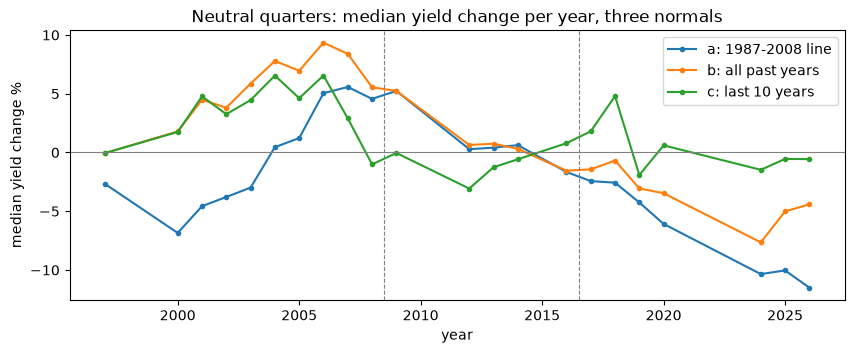

In [16]:
yearly = neutral_cmp.groupby("year")[METHODS].median()
ax = yearly.plot(figsize=(10, 3.5), marker="o", ms=3)
ax.axhline(0, color="grey", lw=0.8)
for boundary in [TRAIN_END + 0.5, VALID_END + 0.5]:
    ax.axvline(boundary, color="grey", ls="--", lw=0.8)
ax.set_ylabel("median yield change %")
ax.set_title("Neutral quarters: median yield change per year, three normals")
plt.show()

### How many cells pass the decided minimum-data rule

Rule: the 10 years before the year being scored must all have a yield.

- **Usable now:** cells where all of 2016 to 2025 have a yield, so a 2026 normal can be built. Out of 1,920 cells (80 provinces x 6 crop types x 4 quarters).
- **Test-period coverage:** of the cell-years in 2017 to 2026 that have a yield, the share that can be scored under (c) (all 10 previous years with a yield and a normal above 0).

In [17]:
all_cells = crops.groupby(CELL).size()
assert len(all_cells) == 1920, len(all_cells)

recent = with_yield[with_yield["year"].between(2016, 2025)].groupby(CELL).size()
usable_now = recent[recent == 10]
print(f"Cells usable now (all of 2016-2025 have a yield): {len(usable_now)} of {len(all_cells)}")
print(usable_now.groupby(level="quarter").size().rename("cells").to_string())

test_yields = with_yield[with_yield["year"] > VALID_END]
test_scored = cmp[(cmp["year"] > VALID_END) & cmp["c: last 10 years"].notna()]
print(f"Test cell-years with a yield: {len(test_yields)}; scorable under (c): {len(test_scored)} "
      f"({len(test_scored) / len(test_yields):.1%})")

Cells usable now (all of 2016-2025 have a yield): 1712 of 1920


quarter
1    418
2    414
3    436
4    444
Test cell-years with a yield: 17626; scorable under (c): 16434 (93.2%)


## 7. Findings

**Join.** 76,800 rows, same as the crop table, so no duplication. 480 rows have no rainfall: 2026 Quarter 4 (incomplete, dropped by the rainfall loader).

**Quarters 1987 to 2026 (160):** 41 El Nino, 42 La Nina, 64 neutral, 13 mixed (left out).

**Cells (1,839 pass the 10-years-in-total check used in sections 3 to 5):**
- 1,661 have 10 or more training years.
- 126 have 2 to 9 training years.
- 52 have no yield before 2009 (mostly Batanes and Dinagat Islands, plus Sulu irrigated palay Quarter 3).
- 171 of the 1,661 have a median training area under 100 ha (15 under 10 ha), so their yields are noisy.

**Huge percents.** A normal that is above 0 but very small gives huge percents (largest about +450,000%), so means are meaningless. Use medians and percentiles.

**Drift of the 1987-2008 line (sections 3 and 4).** Median yield change in neutral quarters: train -0.5%, validate +1.1%, test -6.1%, about -10% by 2024 to 2026. Yield growth slowed, so a line extended from 1987 to 2008 expects more than farms produce.

**Comparing normal-yield fits (section 6).** Median yield change in neutral quarters, same cell-years for all three (train here is 1997 to 2008):

| Normal | Train | Validate | Test | Spread (IQR) in test |
|---|---|---|---|---|
| (a) 1987-2008 line | -0.9 (in-sample) | +0.8 | -6.9 | 35.9 |
| (b) all past years | +5.5 | +0.7 | -4.1 | 16.7 |
| (c) last 10 years | +3.8 | -1.1 | 0.0 | 13.8 |

The last-10-years line has no drift in the test years and the smallest spread in validation and test. Its train median (+3.8) is above 0 because yields were still speeding up in the 1990s and 2000s.

**Minimum-data rule (10 previous years, all with a yield).** 1,712 of 1,920 cells are usable now (all of 2016 to 2025 have a yield): Quarter 1: 418, Quarter 2: 414, Quarter 3: 436, Quarter 4: 444. In the test years, 16,434 of 17,626 cell-years with a yield (93.2%) can be scored.

**El Nino against neutral (median yield change, 1987-2008 line):** train -1.2 vs -0.5, validate -1.7 vs +1.1, test -7.8 vs -6.1. The effect on the same quarter's yield is small, about 1 to 3 points. Rainfall shows a much clearer signal: median 72% of normal in El Nino quarters against 99% in neutral ones.

**Colour options, 2015-16 event (validation, 7 quarters):** PAGASA rainfall bands give 206 green, 308 yellow, 53 red of 567 province-quarters (361 yellow or red). The yield-percentile options (Y1, Y2) give about the same share of red and yellow as any year, so they barely respond to El Nino.

### Decided

1. **Split:** train 1987 to 2008, validate 2009 to 2016, test 2017 to 2026 (same as Layer 1).
2. **Normal yield:** a straight line through the 10 years before each year, extended one year.
3. **Yield change:** (actual - normal) / normal x 100, only where the normal is above 0. Summaries use medians and percentiles, not means.
4. **Minimum data:** the 10 years before the year being scored must all have a yield. Otherwise the app says "not enough data".
5. **El Nino quarter:** at least 2 of its 3 months inside an El Nino event (Layer 1 `find_events`).
6. **Map colours:** PAGASA rainfall bands. Red 40% of normal or less, yellow 41 to 80%, green above 80%. Source: PAGASA Dry Spell/Drought Assessment, 31 Dec 2023. Yield change is shown as a number, not a colour.

### Still open

1. Same quarter or lagged: drought in one quarter may show in the next quarter's harvest. Decide at the model step.
2. What the "normal year" map shows.
3. How the Layer 1 forecast becomes Layer 2 inputs.
4. The final algorithms.
